# Ziel des ML-AnsatzesFeature-Skalierung: 

1. Standardisierung der 5 Composite-Signale mittels StandardScaler.
2. K-Means Clustering ($K=5$): Der Algorithmus sucht völlig eigenständig nach 5 natürlichen Mathematischen Clustern in den Daten.
3. PCA (2D-Projektion): Reduktion der 5 Dimensionen auf 2 Hauptkomponenten ($PC_1, PC_2$), damit wir die Cluster im 2D-Streudiagramm visualisieren können.
4. Vergleich & Alignment

# Zelle 1: Imports & Daten vorbereiten

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# 1. Indizes & Fuzzy-Assignments laden
df_indices = pd.read_csv('data/traveltide_user_perk_indices.csv')
df_fuzzy = pd.read_csv('data/perk_assignments.csv')

index_cols = ['meal_index', 'baggage_index', 'cancellation_index', 'bargain_hunter_index', 'free_night_index']
X = df_indices[index_cols]

# 2. Standardisierung für K-Means
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Daten für {len(df_indices):,} User erfolgreich skaliert.")

Daten für 50,000 User erfolgreich skaliert.


# Zelle 2: K-Means Clustering ($K=5$) & Silhouette Score

In [2]:
# K-Means Modell mit K=5 Clustern anlegen
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df_indices['cluster_ml'] = kmeans.fit_predict(X_scaled)

# Silhouette Score berechnen (auf Stichprobe wegen Performance)
sample_size = min(10000, len(X_scaled))
sil_score = silhouette_score(X_scaled[:sample_size], df_indices['cluster_ml'].iloc[:sample_size])

print(f"=== K-Means Clustering abgeschlossen ===")
print(f"Silhouette Score (N={sample_size}): {sil_score:.4f}")
print("\nVerteilung der Kunden auf die 5 ML-Cluster:")
print(df_indices['cluster_ml'].value_counts().sort_index())

=== K-Means Clustering abgeschlossen ===
Silhouette Score (N=10000): 0.2628

Verteilung der Kunden auf die 5 ML-Cluster:
cluster_ml
0     9921
1     4728
2    16039
3    10343
4     8969
Name: count, dtype: int64


# Zelle 3: PCA (Principal Component Analysis) für 2D-Visualisierung

Erklärte Varianz durch PC1 & PC2: 62.9% (PC1: 37.0%, PC2: 25.9%)


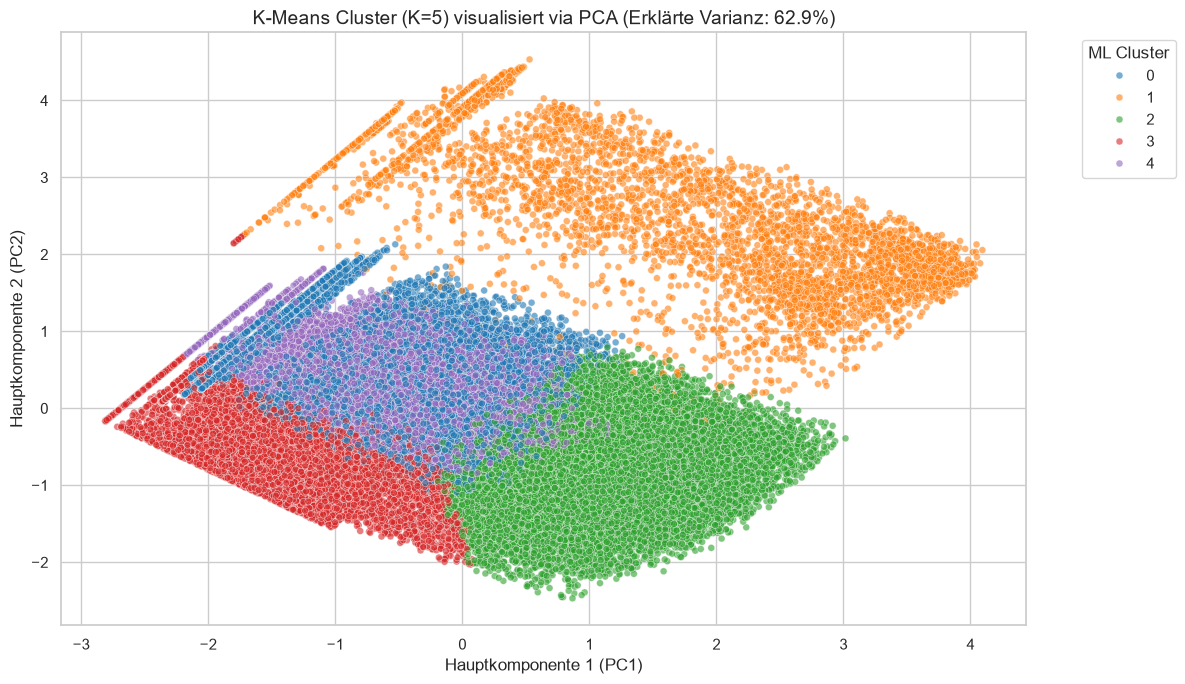

In [3]:
# PCA auf 2 Dimensionen reduzieren
pca = PCA(n_components=2, random_state=42)
pca_components = pca.fit_transform(X_scaled)

df_indices['PC1'] = pca_components[:, 0]
df_indices['PC2'] = pca_components[:, 1]

var_exp = pca.explained_variance_ratio_
print(f"Erklärte Varianz durch PC1 & PC2: {sum(var_exp)*100:.1f}% (PC1: {var_exp[0]*100:.1f}%, PC2: {var_exp[1]*100:.1f}%)")

# Scatterplot der 5 ML-Cluster
plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=df_indices, 
    x='PC1', y='PC2', 
    hue='cluster_ml', 
    palette='tab10', 
    alpha=0.6, 
    s=25
)

plt.title(f"K-Means Cluster (K=5) visualisiert via PCA (Erklärte Varianz: {sum(var_exp)*100:.1f}%)", fontsize=14)
plt.xlabel("Hauptkomponente 1 (PC1)")
plt.ylabel("Hauptkomponente 2 (PC2)")
plt.legend(title="ML Cluster", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Zelle 4: Vergleich: ML Cluster vs. Fuzzy Perk Assignments (Crosstab)

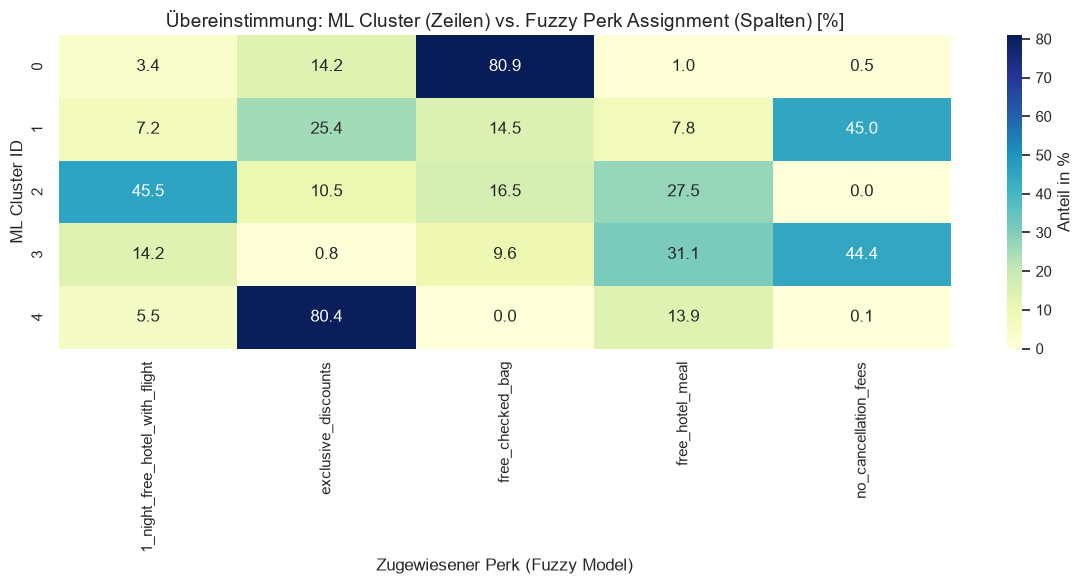

In [4]:
# Merge mit den Fuzzy-Perks
df_comparison = df_indices.merge(df_fuzzy, on='user_id')

# Kreuztabelle erstellen
ct = pd.crosstab(
    df_comparison['cluster_ml'], 
    df_comparison['assigned_perk'], 
    normalize='index'
) * 100

plt.figure(figsize=(12, 6))
sns.heatmap(ct, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={'label': 'Anteil in %'})
plt.title("Übereinstimmung: ML Cluster (Zeilen) vs. Fuzzy Perk Assignment (Spalten) [%]", fontsize=14)
plt.xlabel("Zugewiesener Perk (Fuzzy Model)")
plt.ylabel("ML Cluster ID")
plt.tight_layout()
plt.show()

# Zelle 5 Weitere Cluster-Algorithmen
* **KMeans** geht von kugelförmigen Clustern aus
* **DBSCAN** hat Probleme mit kontinuierlichen Datenwolken, die hier (wie die PCA Visuealiserung zeigte, vorliegen) Da bei Kundenprofilen die Übergangen fließend sind, stuft DBSCAN sher schenll 20-40% der Kudnen als Rauschen ein (-1) 
* Eine eps im 5D-Raum führt kurz gesagt dazu, dass DBSCAN eher einen großen Cluster erkenntg oder 80% der Daten verwirft
* **GMM** *(Gaussian Mixture Model)* könnte hier eine Alternative sein, denn GMM arbietet mit Wahrscheinlilchkeiten (Soft-Clustering), erlaubt unterschiedliche Clsuter-Formen in einem Durchgang, so dass sicher alle Kunden ein Segment zugewiesen bekommen (Kein Rauschen)

In [5]:
from sklearn.cluster import DBSCAN
from sklearn.mixture import GaussianMixture

# 1. DBSCAN Test
dbscan = DBSCAN(eps=0.5, min_samples=50)
df_indices['cluster_dbscan'] = dbscan.fit_predict(X_scaled)

print("=== DBSCAN Ergebnisse ===")
print(df_indices['cluster_dbscan'].value_counts())
# (Du wirst sehen, wie viele Datenpunkte als -1 / Rauschen landen)

# 2. Gaussian Mixture Model (GMM) - Der flexible K-Means-Nachfolger
gmm = GaussianMixture(n_components=5, random_state=42)
df_indices['cluster_gmm'] = gmm.fit_predict(X_scaled)

print("\n=== GMM Ergebnisse (5 Cluster) ===")
print(df_indices['cluster_gmm'].value_counts())

=== DBSCAN Ergebnisse ===
cluster_dbscan
 0     25136
 3     11016
 2      6409
-1      2294
 4      2097
 1      1374
 6       676
 8       389
 5       334
 7       184
 9        53
 10       38
Name: count, dtype: int64

=== GMM Ergebnisse (5 Cluster) ===
cluster_gmm
4    15872
1    12917
2    12907
3     4737
0     3567
Name: count, dtype: int64


Erklärte Gesamtwarianz durch PC1 & PC2: 62.9%
 - PC1 (Hauptkomponente 1): 37.0%
 - PC2 (Hauptkomponente 2): 25.9%


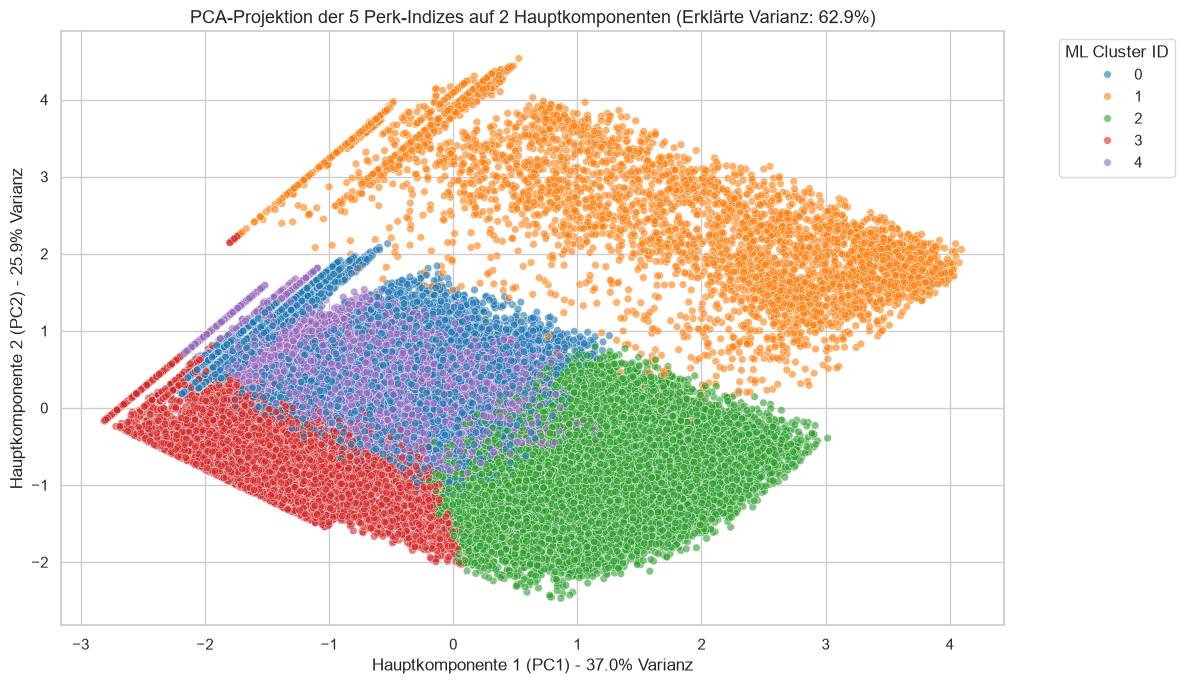

=== PCA Loadings (Einfluss der 5 Indizes auf die Hauptkomponenten) ===
                        PC1    PC2
meal_index            0.540 -0.422
baggage_index         0.347  0.191
cancellation_index    0.280  0.641
bargain_hunter_index  0.374  0.508
free_night_index      0.608 -0.342


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Styling
sns.set_theme(style="whitegrid")

# 1. Daten laden
df_indices = pd.read_csv('data/traveltide_user_perk_indices.csv')
df_fuzzy = pd.read_csv('data/perk_assignments.csv')

index_cols = ['meal_index', 'baggage_index', 'cancellation_index', 'bargain_hunter_index', 'free_night_index']
X = df_indices[index_cols]

# 2. Skalierung & K-Means
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df_indices['cluster_ml'] = kmeans.fit_predict(X_scaled)

# Merge mit den Fuzzy-Assignments für farbliche Gegenüberstellung
df_indices = df_indices.merge(df_fuzzy, on='user_id')

# 3. PCA durchführen
pca = PCA(n_components=2, random_state=42)
pca_components = pca.fit_transform(X_scaled)

# Erklärte Varianz berechnen
var_exp = pca.explained_variance_ratio_
print(f"Erklärte Gesamtwarianz durch PC1 & PC2: {sum(var_exp)*100:.1f}%")
print(f" - PC1 (Hauptkomponente 1): {var_exp[0]*100:.1f}%")
print(f" - PC2 (Hauptkomponente 2): {var_exp[1]*100:.1f}%")

df_indices['PC1'] = pca_components[:, 0]
df_indices['PC2'] = pca_components[:, 1]

var_exp = pca.explained_variance_ratio_

# 4. Scatterplot mit hue='cluster_ml' (bunt)
plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=df_indices, 
    x='PC1', y='PC2', 
    hue='cluster_ml', 
    palette='tab10', 
    alpha=0.6, 
    s=30
)

plt.title(f"PCA-Projektion der 5 Perk-Indizes auf 2 Hauptkomponenten (Erklärte Varianz: {sum(var_exp)*100:.1f}%)", fontsize=13)
plt.xlabel(f"Hauptkomponente 1 (PC1) - {var_exp[0]*100:.1f}% Varianz")
plt.ylabel(f"Hauptkomponente 2 (PC2) - {var_exp[1]*100:.1f}% Varianz")
plt.legend(title="ML Cluster ID", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# 5. Mathematische Überprüfung der Fachmeinung (Loadings Matrix)
loadings = pd.DataFrame(
    pca.components_.T, 
    columns=['PC1', 'PC2'], 
    index=index_cols
)
print("=== PCA Loadings (Einfluss der 5 Indizes auf die Hauptkomponenten) ===")
print(loadings.round(3))

In [8]:
df_indices

,user_id,meal_index,baggage_index,cancellation_index,bargain_hunter_index,free_night_index,cluster_ml,assigned_perk,PC1,PC2
0,55,0.67141,0.97002,0.94416,0.52349,0.44446,1,free_checked_bag,1.662219,2.117294
1,88,0.93878,0.86556,0.45264,0.38132,0.90277,2,free_hotel_meal,1.882352,-1.287812
2,134,0.46166,0.79621,0.45264,0.80586,0.54905,0,exclusive_discounts,0.704240,0.531102
3,207,0.39477,0.84089,0.94416,0.94560,0.25223,1,exclusive_discounts,1.124273,3.405941
4,394,0.93363,0.86556,0.98105,0.91994,0.85866,1,no_cancellation_fees,3.485093,2.029073
...,...,...,...,...,...,...,...,...,...,...
49995,381826,0.23055,0.18697,0.45264,0.06204,0.10499,3,no_cancellation_fees,-2.385946,-0.327283
49996,381831,0.94603,0.37666,0.45264,0.19421,0.99847,2,1_night_free_hotel_with_flight,1.251682,-2.074878
49997,381839,0.46820,0.68779,0.45264,0.34162,0.63772,0,free_checked_bag,0.169068,-0.475509
49998,381847,0.04654,0.54135,0.45264,0.23862,0.10499,0,free_checked_bag,-2.063167,0.493946


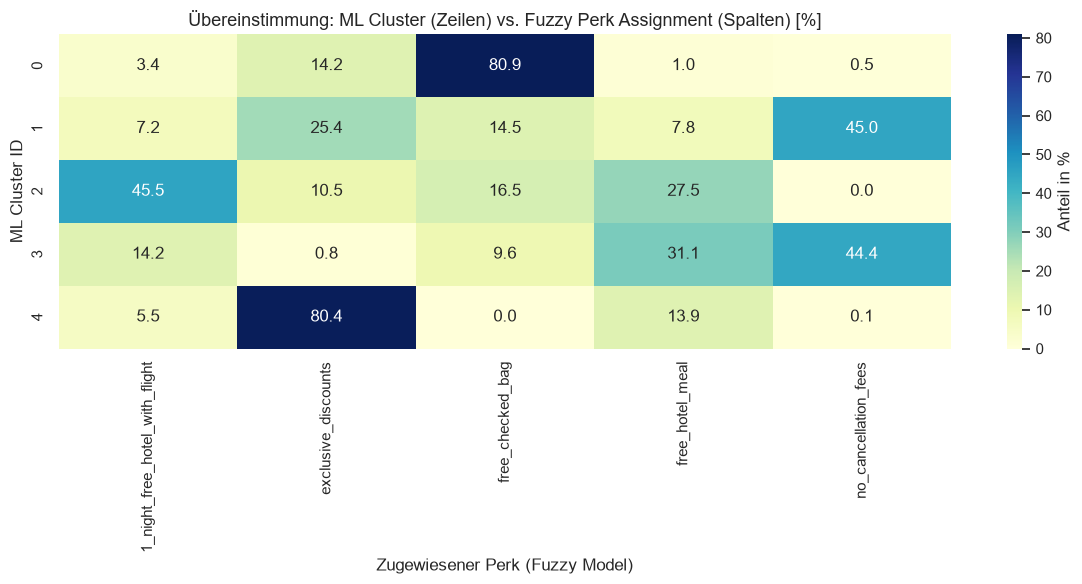

In [7]:
# Einheitliches Dictionary für Benennung in Visualisierungen
PERK_NAMES = {
    'bargain_hunter_index': 'exclusive_discounts',
    'baggage_index': 'free_checked_bag',
    'cancellation_index': 'no_cancellation_fees',
    'meal_index': 'free_hotel_meal',
    'free_night_index': '1_night_free_hotel_with_flight'
}

# Heatmap mit sauberen Zeilen-/Spaltenbeschriftungen plotten
plt.figure(figsize=(12, 6))
sns.heatmap(
    ct, 
    annot=True, 
    fmt=".1f", 
    cmap="YlGnBu", 
    cbar_kws={'label': 'Anteil in %'}
)
plt.title("Übereinstimmung: ML Cluster (Zeilen) vs. Fuzzy Perk Assignment (Spalten) [%]", fontsize=13)
plt.xlabel("Zugewiesener Perk (Fuzzy Model)")
plt.ylabel("ML Cluster ID")
plt.tight_layout()
plt.show()